# eccNET: alternative `eccParam` vs. Standard (Original) vs. Human

This notebook has two independent main sections, each following the same pattern: run one *new* `eccParam` configuration once, then compare it directly against Human data and against the already-existing Standard (Original) results -- without ever recomputing the Standard configuration itself.

- **1. Haupt-Experimente**: the 6 search-asymmetry experiments (`runExp_eccNET.py`). The Standard (Original) results already exist at `vs_exp/eccNET/out/eccNET/` (produced by the original authors' script) and are loaded directly, not recomputed.
- **2. Saccade-Path-Experimente**: the Waldo + NaturalDesign scanpath-similarity experiments (`vs_saccade_exp/runExp.py`), compared against Human/Standard via `ScanpathScorePy` (`vs_saccade_exp/score_analysis.py`) -- a pure NumPy reimplementation of the ScanMatch algorithm (Cristino et al., 2010), `vs_saccade_exp/scanmatch.py`. The original `ScanpathScore`/`ScanMatchPy` needs a MATLAB Runtime 9.7 that could not be gotten working on this machine (no macOS arm64 support, and the specific version doesn't match a full MATLAB Desktop install either -- see notebook history). `scanmatch.py` has been validated against a real MATLAB R2026b installation running the original, open ScanMatch.m toolbox: for identical parameters, it reproduces MATLAB's score bit-for-bit (see scanmatch.py's docstring). What remains unreproducible is the original paper's exact, undisclosed `Xbin`/`Ybin`/`Threshold` choice (baked into kreimanlab's compiled, encrypted `findScore.m` wrapper) -- so absolute scores aren't on the same scale as the old `ss_score/*.npy` cache, only the method itself is verified correct. (`MultiMatchScore`, based on the `multimatch_gaze` library, is also available in `score_analysis.py` as an alternative scanpath metric, but tends to score even dissimilar scanpaths highly -- ScanMatch is more discriminative and is used here as the primary metric.) The Standard (Original)/IVSN/Human scores are recomputed with `ScanpathScorePy` (from the already-existing raw fixation data, no model rerun) into `vs_saccade_exp/out/<dataset>/ss_score_py/`.

## Setup

In [1]:
import sys
import os
import pathlib

_cwd = pathlib.Path.cwd().resolve()
_repo_root = None
for _candidate in [_cwd] + list(_cwd.parents):
    if (_candidate / "vs_exp").is_dir() and (_candidate / "notebooks").is_dir():
        _repo_root = _candidate
        break
if _repo_root is None:
    raise RuntimeError(
        f"Could not locate the VisualSearchAsymmetry repo root from cwd={_cwd}. "
        "Make sure the kernel is started somewhere inside the VisualSearchAsymmetry project."
    )

os.chdir(_repo_root / "vs_exp")

sys.path.insert(0, "eccNET")
sys.path.insert(0, ".")
sys.path.append("..")
sys.path.append("../vs_saccade_exp")

import numpy as np
import matplotlib.pyplot as plt

# vs_exp/data_utils.py and vs_saccade_exp/data_utils.py are two different
# modules that both happen to be called "data_utils" -- runExp_eccNET.py and
# runExp.py each do a bare `from data_utils import ...`, so whichever one is
# importable under sys.modules["data_utils"] at THEIR import time is the one
# they permanently bind. Relying on sys.path order alone can only ever satisfy
# one of them, so inject the correct module into sys.modules right before each
# import instead.
import importlib.util

def _load_as_data_utils(path):
    spec = importlib.util.spec_from_file_location("data_utils", path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    sys.modules["data_utils"] = mod

_load_as_data_utils(str(_repo_root / "vs_exp" / "data_utils.py"))
from runExp_eccNET import run_eccnet_experiment
from rt_plot import gen_RT_data, gen_RT_plot, colors as rt_colors
from eval_asym_metric import calcAsymScore

# vs_saccade_exp imports -- ScanpathScorePy uses scanmatch.py, a pure NumPy
# reimplementation of ScanMatch validated against real MATLAB (no
# MATLAB/ScanMatchPy needed at runtime).
_load_as_data_utils(str(_repo_root / "vs_saccade_exp" / "data_utils.py"))
from runExp import run_saccade_experiment
from score_analysis import ScanpathScorePy

rt_fxn_model = {'slope': 252.359, 'intercept': 376.271}
task_ids = list(range(6))
exps = ['categorization', 'curvature', 'intersection', 'lightning_dir']
base_data_path = "dataset/"
vgg_model_path = "../pretrained_model/vgg16_imagenet_filters.h5"

# Pass this explicitly to every run_eccnet_experiment(...) call so the save
# location is anchored here regardless of the kernel's cwd, matching the
# "./eccNET/out/" path the RT-plot cells below read from.
out_dir = str(_repo_root / "vs_exp" / "eccNET" / "out")

# Same idea for the saccade-path experiments (Section 2).
saccade_base_data_path = str(_repo_root / "vs_saccade_exp" / "dataset") + "/"
saccade_out_dir = str(_repo_root / "vs_saccade_exp" / "out")

print("Resolved repo root:", _repo_root)
print("cwd:", os.getcwd())

Resolved repo root: /Users/nadine/Documents/Uni/Hiwi/Codebase/VisualSearchAsymmetry
cwd: /Users/nadine/Documents/Uni/Hiwi/Codebase/VisualSearchAsymmetry/vs_exp


## 1. Haupt-Experimente (6 Asymmetrie-Experimente)

### 1.1 Parametrisierung & Ausführung (neue eccParam)

In [2]:
# Display Dimensions 
display_dist = 470 #mm 
display_size = [332, 187] #mm 
display_res = [1920, 1080] #px

# deg2px 
tan_c = 0.0194
mm2px = (display_res[0] / display_size[0])
deg2px = display_dist * tan_c * mm2px

# Model Parametrization
eccParam = {}
eccParam['rf_min'] = [2]*5
eccParam['stride'] = [2]*5
eccParam['ecc_slope'] = [0, 0, 1/6, 3/6, 5/6] 
eccParam['deg2px'] = [round(deg2px), round(deg2px/2), round(deg2px/4), round(deg2px/8), round(deg2px/16)] 
eccParam['fovea_size'] = 4
eccParam['rf_quant'] = 1
eccParam['pool_type'] = 'avg'

model_desc = {
    'eccParam': eccParam,
    'ecc_depth': 5,
    'out_layer': [1, 1, 1],
    'comp_layer': 'diff',
    'vgg_model_path': vgg_model_path,
    'model_subname': "_altParam",
}

model_name = run_eccnet_experiment(model_desc, exps=exps, base_data_path=base_data_path, out_dir=out_dir)
print("Run B model name:", model_name)

eccNET_altParam


2026-10-05 21:23:50.390200: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4 Pro
2026-10-05 21:23:50.390245: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-10-05 21:23:50.390252: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.88 GB
2026-10-05 21:23:50.390701: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-05 21:23:50.390974: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


homo_t0:   0%|          | 0/120 [00:00<?, ?it/s]

1/1 [==============================] - 0s 268ms/step


2026-10-05 21:23:51.863752: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-10-05 21:23:52.131425: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


1/1 [==============================] - 0s 11ms/step


... (28 outputs left out)

2026-10-05 21:35:49.351509: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


1/1 [==============================] - 0s 9ms/step


top_down:   0%|          | 0/90 [00:00<?, ?it/s]

1/1 [==============================] - 0s 9ms/step
Run B model name: eccNET_altParam


### 1.2 Ergebnisse neue Parametrisierung

In [6]:
# Human-vs-Model RT plots for Run B
all_fxn_data_B, all_fxn_seq_B = gen_RT_data(model_name, "./eccNET/out/", rt_fxn_model, task_ids)

for n in range(len(all_fxn_seq_B)):
    gen_RT_plot(all_fxn_data_B, all_fxn_seq_B[n], task_ids[n])

print("Saved RT plots to results/rt_plots/" + model_name + "/")

Saved RT plots to results/rt_plots/eccNET_altParam/


### 1.3 Vergleich: Human vs. Standard (Original) vs. neue Parametrisierung

One combined plot per experiment: Human (solid), Standard/Original (dashed), neue Parametrisierung (dash-dot), one color per condition -- built from the same `FxnData` fields (`num_item_rt`, `rt_model`, `rt_model_std`, `rt_hum`, `task`) that `rt_plot.gen_RT_plot` uses, just overlaid on a single axes instead of two side-by-side subplots. The Standard/Original data already exists at `vs_exp/eccNET/out/eccNET/` (produced by the original authors' script) and is loaded directly here, without recomputing it.

In [7]:
# Standard (Original) results already exist on disk (produced by the original
# authors' script) -- load them directly instead of recomputing via
# run_eccnet_experiment(...).
model_name_orig = "eccNET"
all_fxn_data_orig, all_fxn_seq_orig = gen_RT_data(model_name_orig, "./eccNET/out/", rt_fxn_model, task_ids)

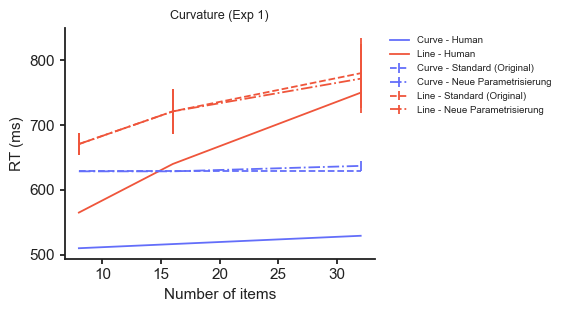

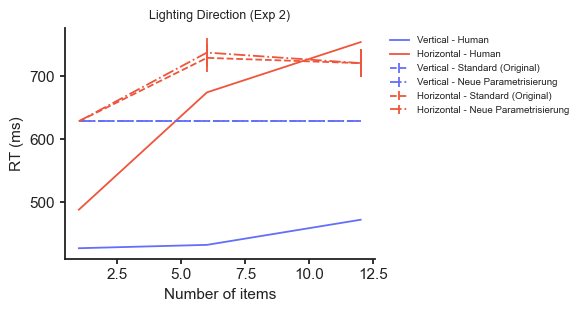

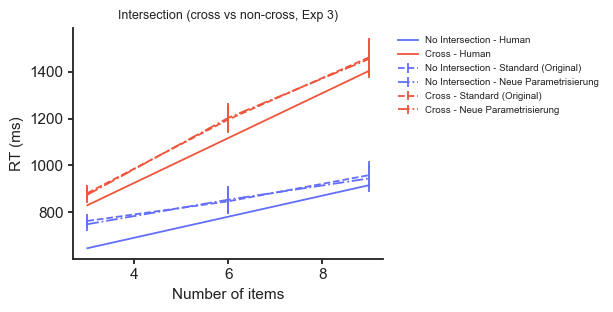

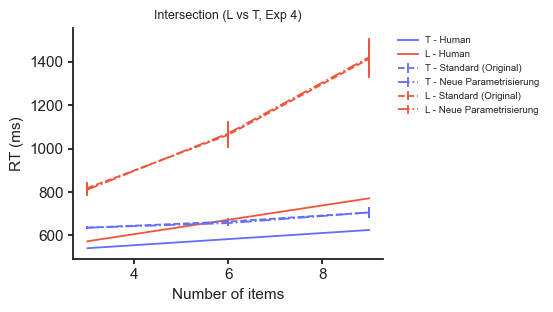

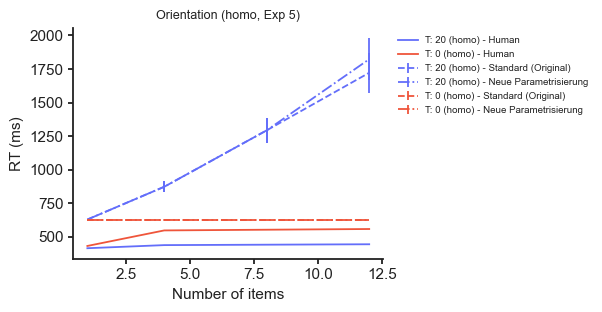

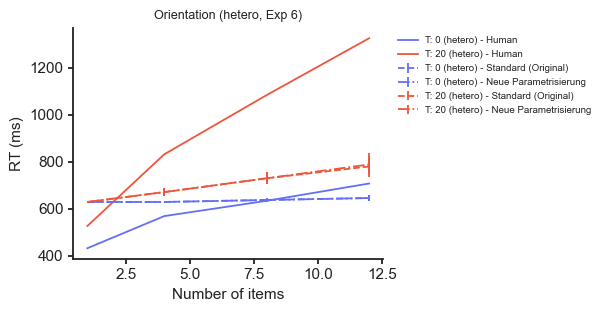

Saved comparison RT plots to results/rt_plots/comparison/


In [8]:
from rt_plot import exp_names

def plot_rt_comparison(all_fxn_data_orig, all_fxn_seq_orig, all_fxn_data_B, all_fxn_seq_B, n):
    """Overlay Human / Standard (Original) / neue Parametrisierung RT-vs-set-size curves for experiment n."""
    task_idx_orig = all_fxn_seq_orig[n]
    task_idx_B = all_fxn_seq_B[n]

    fig, ax = plt.subplots(figsize=(4, 3))

    for i in range(len(task_idx_orig)):
        fxn_orig = all_fxn_data_orig[task_idx_orig[i]]
        fxn_B = all_fxn_data_B[task_idx_B[i]]
        c = rt_colors[i]

        ax.plot(fxn_orig.num_item_rt, fxn_orig.rt_hum, c=c, linestyle='-',
                label=f"{fxn_orig.task} - Human")
        ax.errorbar(fxn_orig.num_item_rt, fxn_orig.rt_model, yerr=fxn_orig.rt_model_std, c=c,
                    linestyle='--', label=f"{fxn_orig.task} - Standard (Original)")
        ax.errorbar(fxn_B.num_item_rt, fxn_B.rt_model, yerr=fxn_B.rt_model_std, c=c,
                    linestyle='-.', label=f"{fxn_B.task} - Neue Parametrisierung")

    ax.set_xlabel("Number of items")
    ax.set_ylabel("RT (ms)")
    ax.set_title(exp_names[n], fontsize=9)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=False, fontsize=7)

    try:
        os.makedirs("results/rt_plots/comparison")
    except FileExistsError:
        pass

    fig.savefig(f"results/rt_plots/comparison/{n}.pdf", dpi=150, bbox_inches="tight")
    plt.show()


for n in task_ids:
    plot_rt_comparison(all_fxn_data_orig, all_fxn_seq_orig, all_fxn_data_B, all_fxn_seq_B, n)

print("Saved comparison RT plots to results/rt_plots/comparison/")

Dataset: Waldo (Python ScanMatch)
human_____________________________________________ 27.3
eccNET_altParamSaccade____________________________ 20.63
eccNET____________________________________________ 20.63
IVSN______________________________________________ 20.38

Dataset: NaturalDesign (Python ScanMatch)
human_____________________________________________ 44.32
eccNET_altParamSaccade____________________________ 26.68
eccNET____________________________________________ 26.68
IVSN______________________________________________ 27.12

cwd: /Users/nadine/Documents/Uni/Hiwi/Codebase/VisualSearchAsymmetry/vs_exp


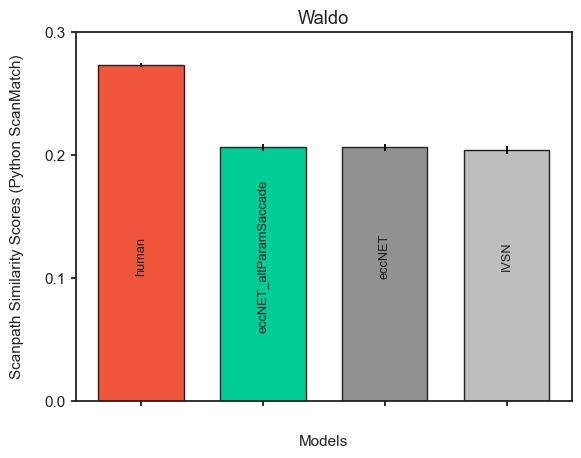

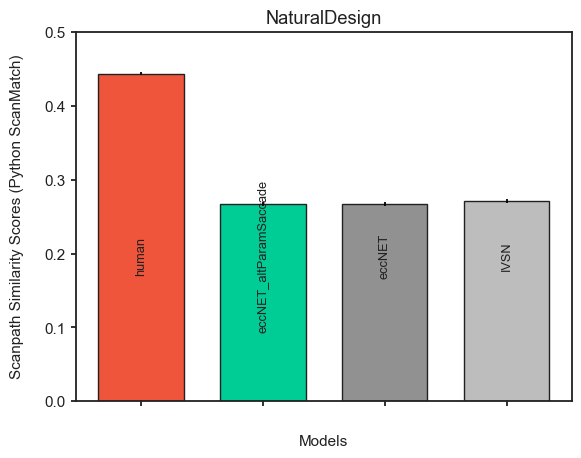

In [ ]:
# score_analysis.py's ScanpathScorePy (and the internal functions it calls) use
# relative paths ("out/...", "results/...") resolved against vs_saccade_exp/,
# so we temporarily chdir there for this call and restore the cwd afterwards.
model_name_saccade = "eccNET_altParam"  # same model as Section 1 (model_subname="_altParam")
_cwd_before = os.getcwd()
os.chdir(_repo_root / "vs_saccade_exp")
try:
    for dataset_name in ["Waldo"]:  # NaturalDesign not computed yet, skip for now
        fix_dir = "out/" + dataset_name + "/fix/"
        # exclude stale eccNET_altParamSaccade.npy from an earlier run -- only
        # eccNET_altParam should show up in the diagram
        model_names = sorted(n for n in os.listdir(fix_dir) if n != "eccNET_altParamSaccade.npy")
        focus = model_names.index(model_name_saccade + ".npy")
        ScanpathScorePy(dataset_name, model_names, focus=focus)
finally:
    os.chdir(_cwd_before)

print("cwd:", os.getcwd())

### 1.4 Asymmetry Index Vergleich

Mean Asymmetry Index (`eval_asym_metric.calcAsymScore`) for Humans, Standard (Original), and neue Parametrisierung, plotted as a single bar chart -- modeled on `generateResults.py`'s `generateAsymIndex()`.

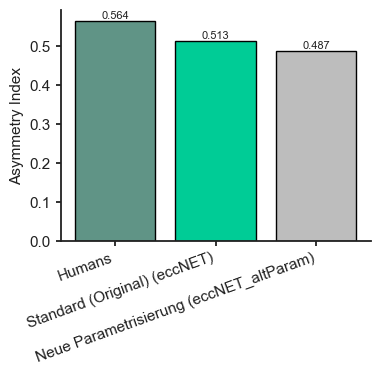

Humans: 0.5644662483776303 | Standard (Original): 0.5125805022830194 | Neue Parametrisierung: 0.48657338853796817


In [9]:
# Human AI does not depend on which model's all_fxn_data/all_fxn_seq is passed in
# (human_slope/rt_hum are attached per condition regardless of model), so either
# run's data can be used to compute it -- matching generateAsymIndex()'s behavior.
ai_human = np.mean(calcAsymScore(all_fxn_data_orig, all_fxn_seq_orig, human=True)[0])
ai_orig = np.mean(calcAsymScore(all_fxn_data_orig, all_fxn_seq_orig)[0])
ai_B = np.mean(calcAsymScore(all_fxn_data_B, all_fxn_seq_B)[0])

labels = ["Humans", f"Standard (Original) ({model_name_orig})", f"Neue Parametrisierung ({model_name})"]
scores = [ai_human, ai_orig, ai_B]
bar_colors = ["#609486", "#00CC96", "#BDBDBD"]

fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(labels, scores, color=bar_colors, edgecolor="#000000")
ax.set_ylabel("Asymmetry Index")
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.xticks(rotation=20, ha='right')

for i, v in enumerate(scores):
    ax.text(i, v, f"{v:.3f}", ha='center', va='bottom', fontsize=8)

fig.savefig("results/asymIndexBarPlot_comparison.pdf", dpi=200, bbox_inches="tight")
plt.show()

print("Humans:", ai_human, "| Standard (Original):", ai_orig, "| Neue Parametrisierung:", ai_B)

## 2. Saccade-Path-Experimente (Waldo + NaturalDesign)

Vergleicht komplette Fixationssequenzen (Scanpaths) gegen menschliche Eyetracking-Daten via `ScanpathScorePy` (`vs_saccade_exp/score_analysis.py`), einer gegen echtes MATLAB validierten Python/NumPy-Reimplementierung des ScanMatch-Algorithmus (`vs_saccade_exp/scanmatch.py`) -- auf den natürlichen Suchbild-Datensätzen `Waldo` und `NaturalDesign` (anders als die synthetischen 6 Hauptexperimente oben). Analog zu Section 1: nur die neue Parametrisierung wird neu berechnet (Modell-Lauf), Human/IVSN/Standard (Original) Scanpath-Scores werden aus den bereits vorhandenen Fixationsdaten neu berechnet (`vs_saccade_exp/out/<dataset>/ss_score_py/`).

### 2.1 Parametrisierung & Ausführung (neue eccParam)

In [18]:
# eccNET parameters -- same model settings as Section 1's new parametrization
# (eccParam in cell 5): same ecc_slope and the same display-geometry deg2px
# formula, reused here for the saccade-path experiments.
# eccParam_saccade = {}
# eccParam_saccade['rf_min'] = [2]*5
# eccParam_saccade['stride'] = [2]*5
# eccParam_saccade['ecc_slope'] = [0, 0, 1/6, 3/6, 5/6]
# eccParam_saccade['deg2px'] = [round(deg2px), round(deg2px/2), round(deg2px/4), round(deg2px/8), round(deg2px/16)]
# eccParam_saccade['fovea_size'] = 4
# eccParam_saccade['rf_quant'] = 1
# eccParam_saccade['pool_type'] = 'avg'

# model_desc_saccade = {
#     'eccParam': eccParam,
#     'ecc_depth': 5,
#     'out_layer': [1, 1, 1],
#     'comp_layer': 'diff',
#     'vgg_model_path': vgg_model_path,
#     'model_subname': "_altParamSaccade",
# }


import sys
import importlib
import importlib.util
import runExp_eccNET
import runExp

def _load_as_data_utils(path):
    spec = importlib.util.spec_from_file_location("data_utils", path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    sys.modules["data_utils"] = mod

# runExp_eccNET.py (Section 1) needs vs_exp's data_utils
_load_as_data_utils(str(_repo_root / "vs_exp" / "data_utils.py"))
importlib.reload(runExp_eccNET)
from runExp_eccNET import run_eccnet_experiment

# runExp.py (Section 2, Waldo/NaturalDesign) needs vs_saccade_exp's data_utils
_load_as_data_utils(str(_repo_root / "vs_saccade_exp" / "data_utils.py"))
importlib.reload(runExp)

#model_name_saccade = run_saccade_experiment(model_desc_saccade, datasets=["Waldo", "NaturalDesign"],
model_name_saccade = run_saccade_experiment(model_desc, datasets=["Waldo"], 
                                             base_data_path=saccade_base_data_path, out_dir=saccade_out_dir)
print("Saccade model name:", model_name_saccade)

eccNET_altParam


Waldo:   0%|          | 0/67 [00:00<?, ?it/s]2026-10-05 22:55:47.309189: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


1/1 [==============================] - 0s 237ms/step


2026-10-05 22:55:47.600297: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


1/1 [==============================] - 0s 88ms/step


Waldo:   1%|▏         | 1/67 [00:03<03:39,  3.32s/it]

... (129 outputs left out)

Waldo:  99%|█████████▊| 66/67 [23:50<00:33, 33.36s/it]

1/1 [==============================] - 0s 86ms/step


Waldo: 100%|██████████| 67/67 [23:53<00:00, 21.39s/it]

Saccade model name: eccNET_altParam


### 2.2 ScanpathScore (ScanMatch) Vergleich: Human vs. Standard (Original) vs. neue Parametrisierung

Dataset: Waldo (Python ScanMatch)
human_____________________________________________ 27.3
eccNET____________________________________________ 20.63
eccNET_altParam___________________________________ 20.34
IVSN______________________________________________ 20.38

cwd: /Users/nadine/Documents/Uni/Hiwi/Codebase/VisualSearchAsymmetry/vs_exp
def ScanpathScorePy(dataset_name, model_names, focus):
    """Pure-Python ScanMatch equivalent of ScanpathScore (no ScanMatchPy/MATLAB
    needed) -- see the module-level comment above for why results aren't mixed
    with the MATLAB-computed ss_score/ cache."""
    ss_dir = "out/" + dataset_name + "/ss_score_py/"
    try:
        os.makedirs(ss_dir)
    except FileExistsError:
        pass

    __ss_scoreHvH_py(dataset_name)
    __ss_score_py(dataset_name, model_names)

    calc_scores = os.listdir(ss_dir)

    if calc_scores[0] != 'human.npy':
        tmp = calc_scores[0]
        calc_scores.remove('human.npy')
        calc_scores.append(copy.deepcopy(

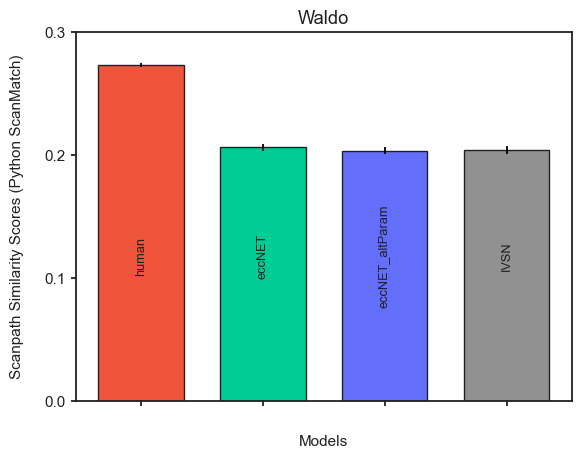

In [20]:
import importlib
import score_analysis
importlib.reload(score_analysis)
from score_analysis import ScanpathScorePy

# score_analysis.py's ScanpathScorePy (and the internal functions it calls) use
# relative paths ("out/...", "results/...") resolved against vs_saccade_exp/,
# so we temporarily chdir there for this call and restore the cwd afterwards.
model_name_saccade = "eccNET_altParam"  # same model as Section 1 (model_subname="_altParam")
_cwd_before = os.getcwd()
os.chdir(_repo_root / "vs_saccade_exp")
try:
    for dataset_name in ["Waldo"]:  # NaturalDesign not computed yet, skip for now
        fix_dir = "out/" + dataset_name + "/fix/"
        # exclude stale eccNET_altParamSaccade.npy from an earlier run -- only
        # eccNET_altParam should show up in the diagram
        model_names = sorted(n for n in os.listdir(fix_dir) if n != "eccNET_altParamSaccade.npy")
        focus = model_names.index(model_name_saccade + ".npy")
        ScanpathScorePy(dataset_name, model_names, focus=focus)
finally:
    os.chdir(_cwd_before)

print("cwd:", os.getcwd())

import inspect
print(inspect.getsource(ScanpathScorePy))